In [1]:
!pip install "numba>=0.60.0,<0.62.0" "numba-cuda>=0.22.2,<0.23.0" "cuda-core==0.3.1"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.3 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of numba-cuda to determine which version is compatible with other requirements. This could take a while.
ERROR: Cannot install cuda-core==0.3.1 and numba-cuda==0.22.2 because these package versions have conflicting dependencies.

The conflict is caused by:
    The user requested cuda-core==0.3.1
    numba-cuda 0.22.2 depends on cuda-core<1.0.0 and >=0.3.2

To fix this you could try to:
1. loosen the range of package versions you've specified
2. remove package versions to allow pip to attempt to solve the dependency conflict

ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.3/41.3 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 20.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 98.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23

In [3]:
import os
import glob
import yaml
import shutil
from collections import Counter
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [4]:
import yaml

base_path = '/kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo' 

data = {
    'train': [
        f'{base_path}/dataset_v3_with_negatives/train/images',
        f'{base_path}/invasive-plants/train/images'
    ],
    'val': [
        f'{base_path}/dataset_v3_with_negatives/val/images',
        f'{base_path}/invasive-plants/val/images'
    ],
    'test': [
        f'{base_path}/dataset_v3_with_negatives/test/images',
        f'{base_path}/invasive-plants/test/images'
    ],
    'nc': 5, 
    'names': [
        'Vachellia nilotica', 
        'Ageratum conyzoides', 
        'Lantana camara', 
        'Clitoria ternatea', 
        'Merremia hederacea'
    ]
}

# Save it to the working directory
with open('/kaggle/working/merged_data.yaml', 'w') as f:
    yaml.dump(data, f, default_flow_style=False)
    
print("Custom data.yaml created successfully!")

Custom data.yaml created successfully!


In [5]:
yaml_path = "/kaggle/working/merged_data.yaml"

with open(yaml_path, "r") as f:
    data = yaml.safe_load(f)

data

{'names': ['Vachellia nilotica',
  'Ageratum conyzoides',
  'Lantana camara',
  'Clitoria ternatea',
  'Merremia hederacea'],
 'nc': 5,
 'test': ['/kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/dataset_v3_with_negatives/test/images',
  '/kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/invasive-plants/test/images'],
 'train': ['/kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/dataset_v3_with_negatives/train/images',
  '/kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/invasive-plants/train/images'],
 'val': ['/kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/dataset_v3_with_negatives/val/images',
  '/kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/invasive-plants/val/images']}

In [6]:
dataset1 = f"{base_path}/dataset_v3_with_negatives"
dataset2 = f"{base_path}/invasive-plants"

splits = ["train", "val", "test"]

for split in splits:
    # Path untuk dataset pertama
    img_dir_ds1 = f"{dataset1}/{split}/images"
    label_dir_ds1 = f"{dataset1}/{split}/labels"
    
    # Path untuk dataset kedua
    img_dir_ds2 = f"{dataset2}/{split}/images"
    label_dir_ds2 = f"{dataset2}/{split}/labels"

    # Menghitung isi di dataset pertama
    images_ds1 = glob.glob(img_dir_ds1 + "/*")
    labels_ds1 = glob.glob(label_dir_ds1 + "/*.txt")
    
    # Menghitung isi di dataset kedua
    images_ds2 = glob.glob(img_dir_ds2 + "/*")
    labels_ds2 = glob.glob(label_dir_ds2 + "/*.txt")

    # Menjumlahkan total
    total_images = len(images_ds1) + len(images_ds2)
    total_labels = len(labels_ds1) + len(labels_ds2)

    print(f"SPLIT: {split.upper()}")
    print(f"- Dataset 1 (v3_with_negatives) : {len(images_ds1)} images, {len(labels_ds1)} labels")
    print(f"- Dataset 2 (invasive-plants)   : {len(images_ds2)} images, {len(labels_ds2)} labels")
    print(f"> TOTAL GABUNGAN                : {total_images} images, {total_labels} labels")
    print("-" * 55)

SPLIT: TRAIN
- Dataset 1 (v3_with_negatives) : 113 images, 113 labels
- Dataset 2 (invasive-plants)   : 958 images, 958 labels
> TOTAL GABUNGAN                : 1071 images, 1071 labels
-------------------------------------------------------
SPLIT: VAL
- Dataset 1 (v3_with_negatives) : 22 images, 22 labels
- Dataset 2 (invasive-plants)   : 274 images, 274 labels
> TOTAL GABUNGAN                : 296 images, 296 labels
-------------------------------------------------------
SPLIT: TEST
- Dataset 1 (v3_with_negatives) : 15 images, 15 labels
- Dataset 2 (invasive-plants)   : 138 images, 138 labels
> TOTAL GABUNGAN                : 153 images, 153 labels
-------------------------------------------------------


In [7]:
names = {
    0: "Vachellia nilotica",
    1: "Ageratum conyzoides",
    2: "Lantana camara",
    3: "Clitoria ternatea",
    4: "Merremia hederacea"
}

def check_labels(split):
    label_dir = f"/content/working_dataset/{split}/labels"
    label_files = glob.glob(label_dir + "/*.txt")

    class_count = Counter()
    empty_labels = 0
    invalid_lines = 0

    for file in label_files:
        if os.path.getsize(file) == 0:
            empty_labels += 1
            continue

        with open(file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) != 5:
                    invalid_lines += 1
                    continue

                cls = int(float(parts[0]))
                x, y, w, h = map(float, parts[1:])

                if cls not in names:
                    invalid_lines += 1
                    continue

                if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
                    invalid_lines += 1
                    continue

                class_count[cls] += 1

    print(f"\nSplit: {split}")
    print("Label kosong:", empty_labels)
    print("Label invalid:", invalid_lines)
    print("Distribusi kelas:")

    for cls_id, count in sorted(class_count.items()):
        print(f"{cls_id} - {names[cls_id]}: {count}")

for split in ["train", "val", "test"]:
    check_labels(split)


Split: train
Label kosong: 0
Label invalid: 0
Distribusi kelas:

Split: val
Label kosong: 0
Label invalid: 0
Distribusi kelas:

Split: test
Label kosong: 0
Label invalid: 0
Distribusi kelas:


In [8]:
from ultralytics import YOLO
import os
from pathlib import Path

# Path dataset di Colab
data_yaml = yaml_path

# Folder penyimpanan hasil training di Google Drive
drive_project_path = "/kaggle/working/YOLO_Training_Runs"

os.makedirs(drive_project_path, exist_ok=True)

# Load model YOLO11s
model_path = Path('/kaggle/input/datasets/miaikoo/best-model-epan/best_model.pt')
model = YOLO(model_path)

results = model.train(
    data=data_yaml,
    epochs=100,
    patience=20,
    imgsz=768,
    batch=8,

    optimizer="AdamW",
    lr0=0.0005,
    lrf=0.01,
    weight_decay=0.0005,
    cos_lr=True,

    # Augmentasi ringan untuk dataset tanaman
    hsv_h=0.015,
    hsv_s=0.4,
    hsv_v=0.25,
    degrees=8.0,
    translate=0.1,
    scale=0.4,
    fliplr=0.5,
    flipud=0.0,

    mosaic=0.2,
    mixup=0.0,
    copy_paste=0.0,

    # Hasil langsung masuk Google Drive
    project=drive_project_path,
    name="yolo11s_img768_adamw",

    device=0,
    workers=2,
    exist_ok=True
)

Ultralytics 8.4.63 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/merged_data.yaml, degrees=8.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.4, hsv_v=0.25, imgsz=768, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/kaggle/input/datasets/miaikoo/best-model-epan/best_model.pt, momentum=0.937, mosaic=0.2, multi_scale=0.0, name=yolo11s_img768_adamw, nbs=64, nms=False, opset=None

In [9]:
import os

best_model_path = f"{drive_project_path}/yolo11s_img768_adamw/weights/best.pt"

print("Best model ada:", os.path.exists(best_model_path))
print(best_model_path)

Best model ada: True
/kaggle/working/YOLO_Training_Runs/yolo11s_img768_adamw/weights/best.pt


In [10]:
from ultralytics import YOLO

best_model_path = f"{drive_project_path}/yolo11s_img768_adamw/weights/best.pt"

model = YOLO(best_model_path)

metrics = model.val(
    data=data_yaml,
    split="val",
    imgsz=768,
    batch=8,
    device=0
)

Ultralytics 8.4.63 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 101 layers, 9,414,735 parameters, 0 gradients, 21.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 367.8±387.7 MB/s, size: 639.0 KB)
val: Scanning /kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/dataset_v3_with_negatives/val/labels... 296 images, 47 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 296/296 692.3it/s 0.4s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/dataset_v3_with_negatives/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 37/37 6.5it/s 5.7s
                   all        296        447      0.859      0.876      0.915      0.666
    Vachellia nilotica         54        136      0.833      0.816      0.882      0.544
   Ageratum conyzoides         58         93      0.838      0

In [11]:
import glob

test_images_ds1 = glob.glob(f"{base_path}/dataset_v3_with_negatives/test/images/*.*")
test_images_ds2 = glob.glob(f"{base_path}/invasive-plants/test/images/*.*")

all_test_images = test_images_ds1 + test_images_ds2

print(f"Memulai prediksi untuk {len(all_test_images)} gambar...")

results = model.predict(
    source=all_test_images,
    imgsz=768,
    conf=0.25,
    save=True,
    
    # working directory Kaggle
    project="/kaggle/working/YOLO_Training_Runs",
    name="yolo11s_test_predictions",
    exist_ok=True
)

Memulai prediksi untuk 153 gambar...

0: 768x768 (no detections), 13.3ms
1: 768x768 (no detections), 13.3ms
2: 768x768 (no detections), 13.3ms
3: 768x768 1 Clitoria ternatea, 13.3ms
4: 768x768 (no detections), 13.3ms
5: 768x768 2 Clitoria ternateas, 13.3ms
6: 768x768 (no detections), 13.3ms
7: 768x768 (no detections), 13.3ms
8: 768x768 (no detections), 13.3ms
9: 768x768 (no detections), 13.3ms
10: 768x768 1 Lantana camara, 13.3ms
11: 768x768 (no detections), 13.3ms
12: 768x768 (no detections), 13.3ms
13: 768x768 (no detections), 13.3ms
14: 768x768 (no detections), 13.3ms
15: 768x768 (no detections), 13.3ms
16: 768x768 1 Ageratum conyzoides, 13.3ms
17: 768x768 2 Ageratum conyzoidess, 13.3ms
18: 768x768 2 Ageratum conyzoidess, 13.3ms
19: 768x768 (no detections), 13.3ms
20: 768x768 2 Merremia hederaceas, 13.3ms
21: 768x768 (no detections), 13.3ms
22: 768x768 1 Merremia hederacea, 13.3ms
23: 768x768 2 Lantana camaras, 13.3ms
24: 768x768 1 Lantana camara, 13.3ms
25: 768x768 1 Merremia heder

In [12]:
# import glob
# import matplotlib.pyplot as plt
# import cv2

# pred_dir = "/content/drive/MyDrive/YOLO_Training_Runs/yolo11s_test_predictions"

# pred_images = glob.glob(pred_dir + "/*.jpg") + glob.glob(pred_dir + "/*.png") + glob.glob(pred_dir + "/*.jpeg")

# print("Jumlah hasil prediksi:", len(pred_images))

# for img_path in pred_images[:5]:
#     img = cv2.imread(img_path)
#     img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

#     plt.figure(figsize=(8, 8))
#     plt.imshow(img)
#     plt.axis("off")
#     plt.title(img_path.split("/")[-1])
#     plt.show()

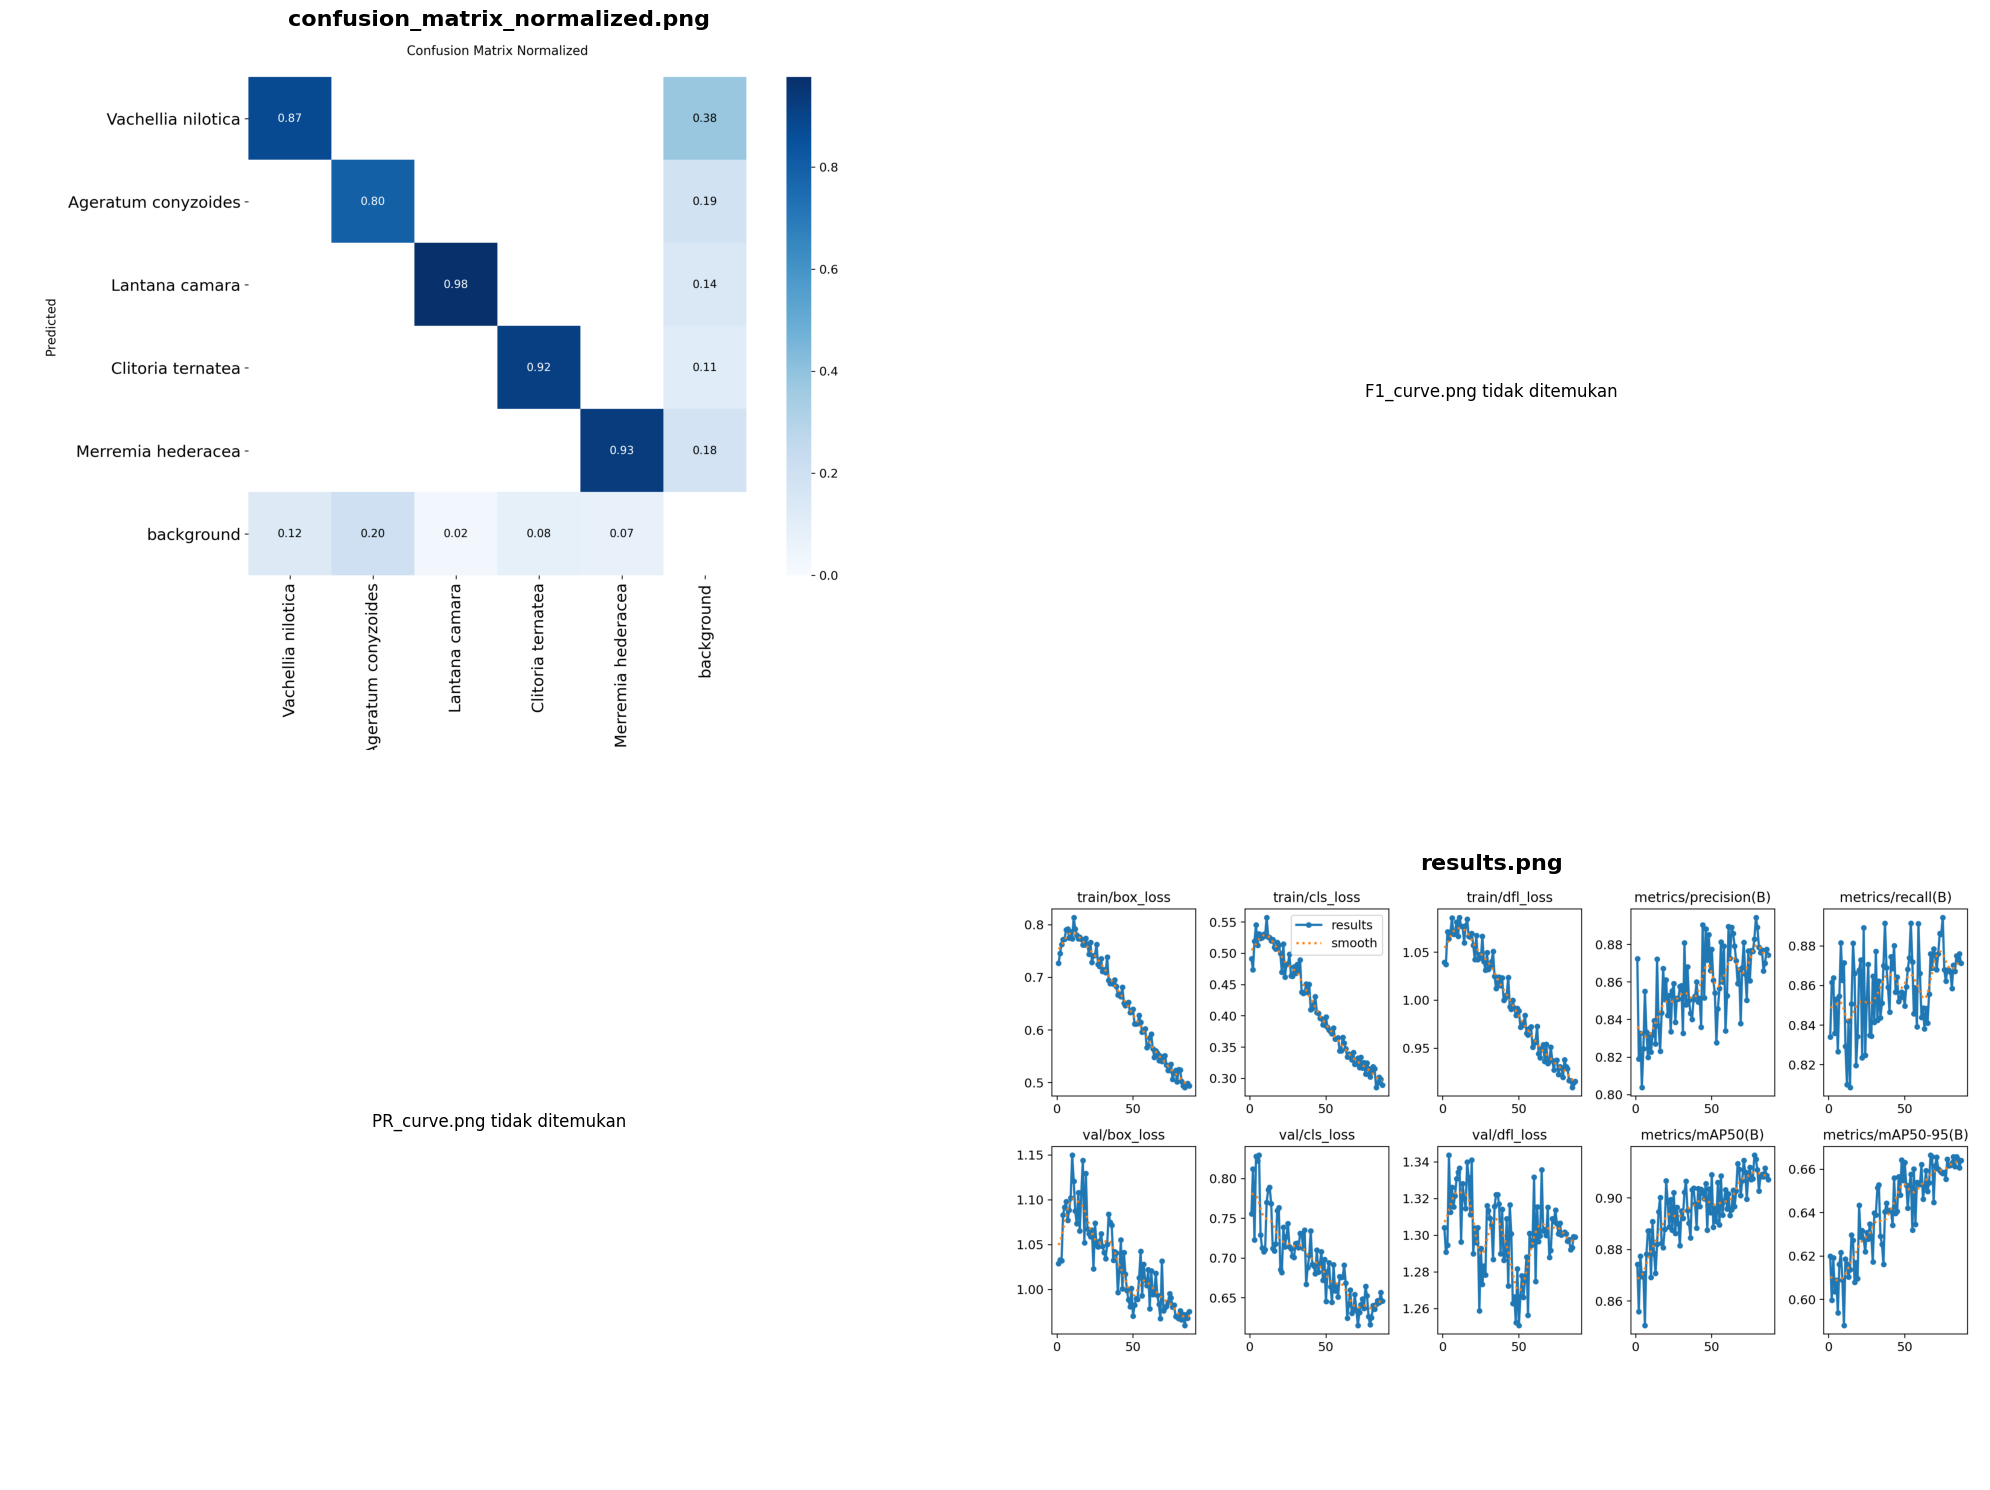

In [13]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

val_dir = f"{drive_project_path}/yolo11s_img768_adamw"

# Daftar nama file metrik bawaan YOLO
images_to_show = [
    "confusion_matrix_normalized.png", 
    "F1_curve.png", 
    "PR_curve.png", 
    "results.png"
]

plt.figure(figsize=(20, 15))

for i, img_name in enumerate(images_to_show):
    img_path = os.path.join(val_dir, img_name)
    
    plt.subplot(2, 2, i + 1)
    if os.path.exists(img_path):
        img = mpimg.imread(img_path)
        plt.imshow(img)
        plt.axis("off")
        plt.title(img_name, fontsize=16, fontweight='bold')
    else:
        # Jika gambar tidak ketemu, tampilkan teks
        plt.text(0.5, 0.5, f"{img_name} tidak ditemukan", 
                 horizontalalignment='center', verticalalignment='center', fontsize=12)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import glob

# 1. Ambil SATU gambar sample dari dataset test untuk divisualisasikan
# Kita ambil gambar pertama dari dataset_v3_with_negatives sebagai contoh
sample_images = glob.glob(f"{base_path}/dataset_v3_with_negatives/test/images/*.jpg")
sample_image = sample_images[0] if sample_images else None

if sample_image:
    print(f"Melakukan visualisasi XAI untuk: {sample_image}")
    
    # 2. Jalankan prediksi dengan parameter visualize=True
    results_xai = model.predict(
        source=sample_image,
        imgsz=768,
        conf=0.25,
        visualize=True,  # <--- INI KUNCI UNTUK XAI
        save=True,
        project="/kaggle/working/YOLO_Training_Runs",
        name="yolo11s_xai_features",
        exist_ok=True
    )
    
    print("\n✅ Proses selesai!")
    print("Buka panel Kaggle Data -> Output.")
    print("Hasil visualisasi per layer tersimpan di: /kaggle/working/YOLO_Training_Runs/yolo11s_xai_features")
    
else:
    print("Gambar test tidak ditemukan, cek kembali path-nya.")

Melakukan visualisasi XAI untuk: /kaggle/input/datasets/miaikoo/invasive-plant-species-object-detection-yolo/dataset_v3_with_negatives/test/images/test_negative_0001.jpg

Saving /kaggle/working/YOLO_Training_Runs/yolo11s_xai_features/test_negative_0001/stage0_Conv_features.png... (32/32)
Saving /kaggle/working/YOLO_Training_Runs/yolo11s_xai_features/test_negative_0001/stage1_Conv_features.png... (32/64)
Saving /kaggle/working/YOLO_Training_Runs/yolo11s_xai_features/test_negative_0001/stage2_C3k2_features.png... (32/128)
Saving /kaggle/working/YOLO_Training_Runs/yolo11s_xai_features/test_negative_0001/stage3_Conv_features.png... (32/128)
Saving /kaggle/working/YOLO_Training_Runs/yolo11s_xai_features/test_negative_0001/stage4_C3k2_features.png... (32/256)
Saving /kaggle/working/YOLO_Training_Runs/yolo11s_xai_features/test_negative_0001/stage5_Conv_features.png... (32/256)
Saving /kaggle/working/YOLO_Training_Runs/yolo11s_xai_features/test_negative_0001/stage6_C3k2_features.png... (32/256

Menemukan 23 file feature map.


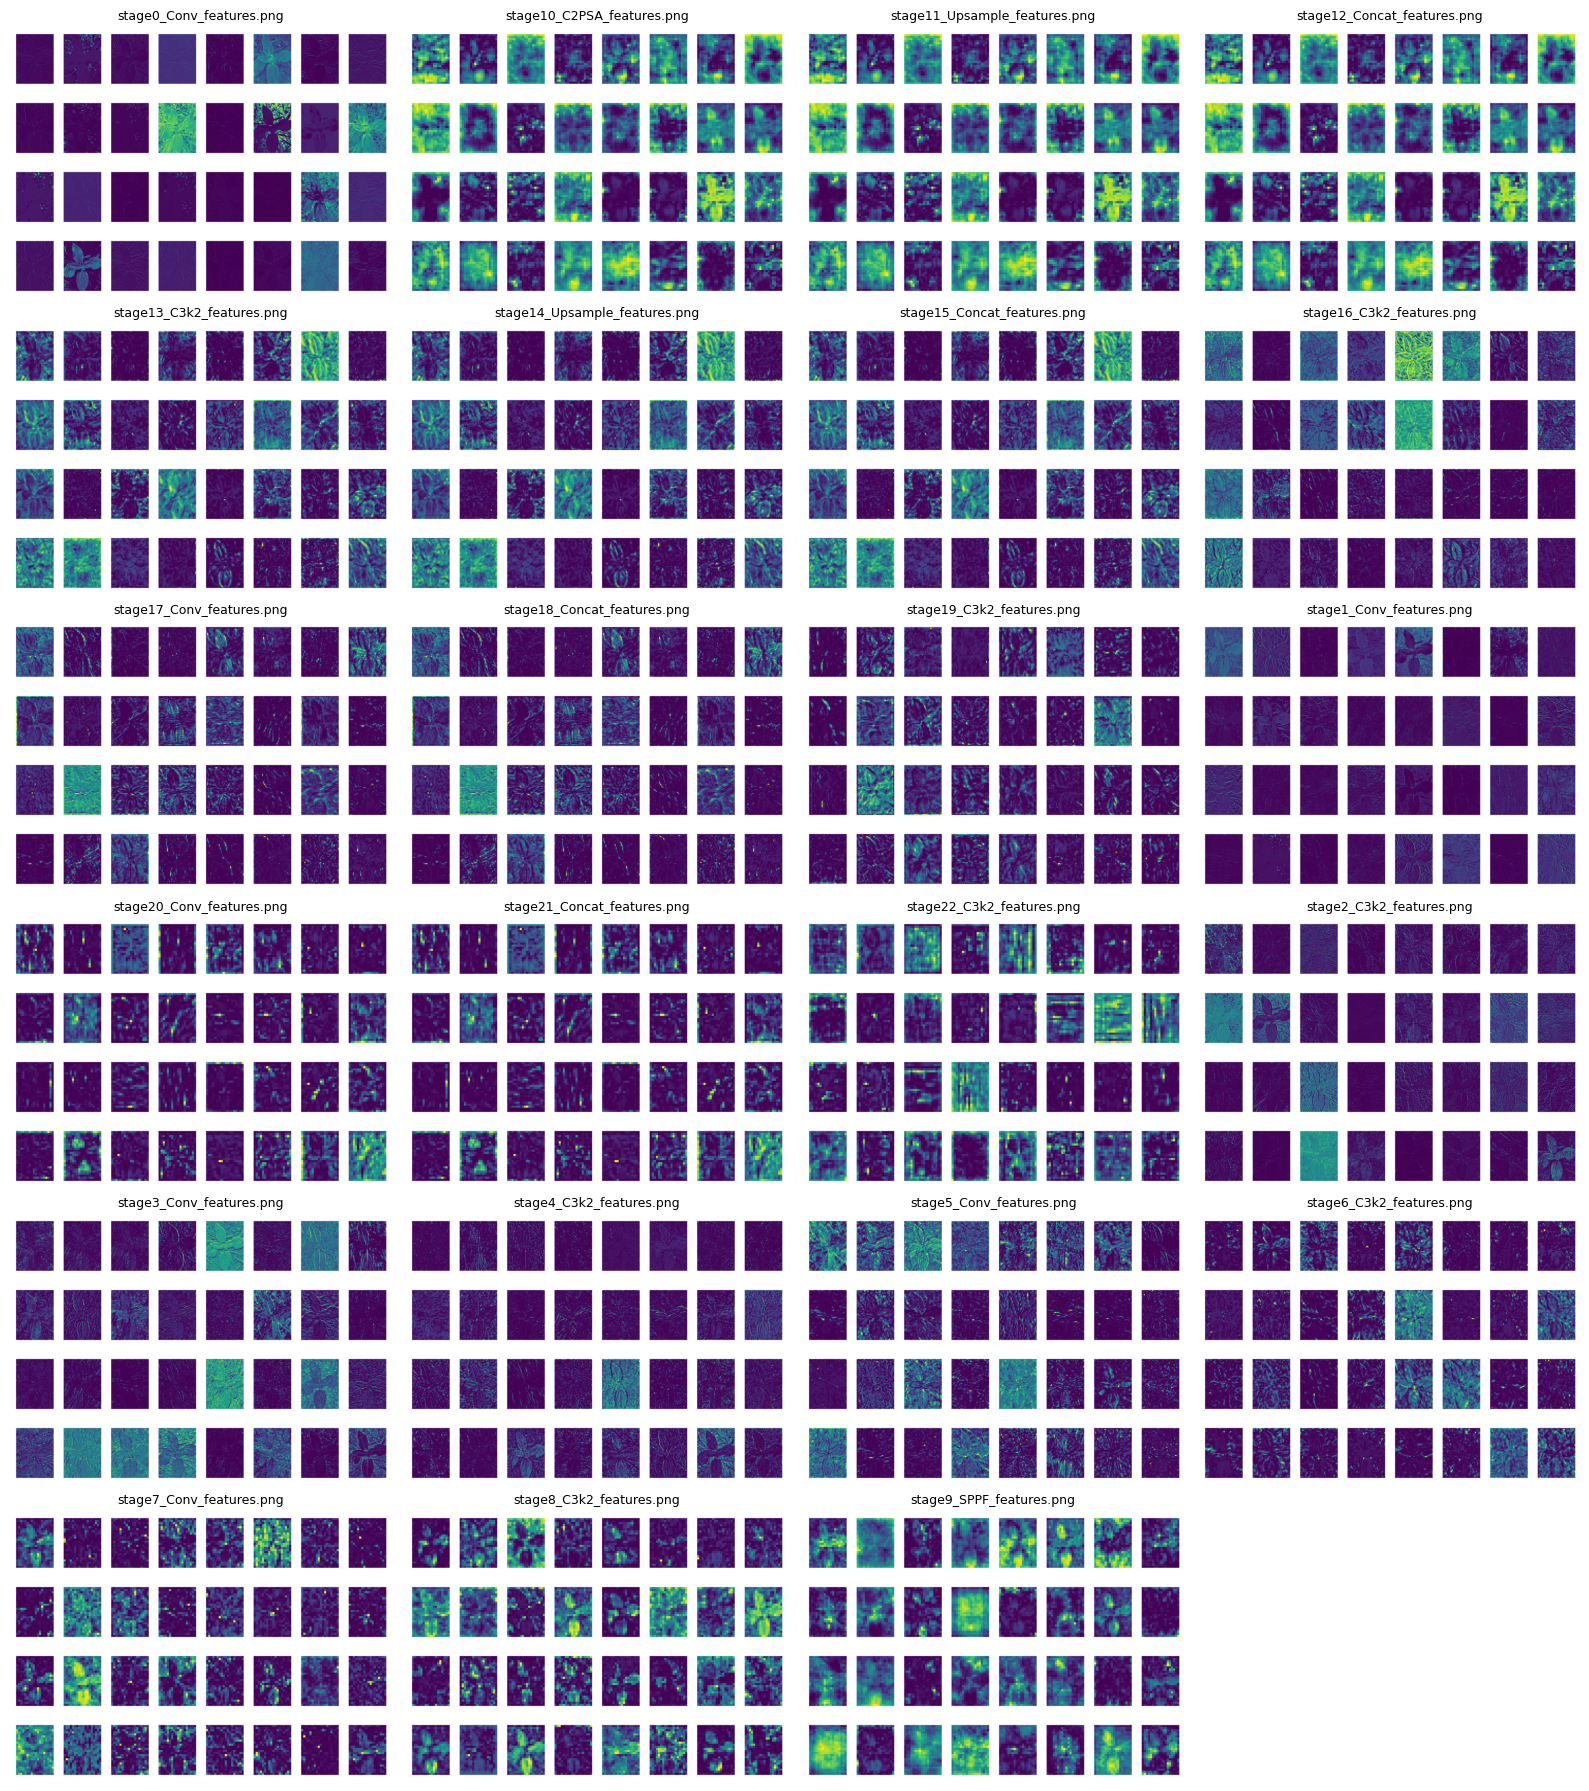

In [15]:
import glob
import os
import math
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# 1. Path ke folder utama hasil XAI
xai_dir = "/kaggle/working/YOLO_Training_Runs/yolo11s_xai_features"

# 2. Cari semua file .png di dalam folder tersebut dan subfoldernya (recursive)
# YOLO biasanya membuat subfolder lagi di dalam folder tersebut dengan nama gambar aslimu
feature_maps = glob.glob(f"{xai_dir}/**/*.png", recursive=True)

# Jika tidak ditemukan dengan pola di atas, coba cari di folder utama langsung
if not feature_maps:
    feature_maps = glob.glob(f"{xai_dir}/*.png")

print(f"Menemukan {len(feature_maps)} file feature map.")

if feature_maps:
    # -----------------------------------------------------------
    # ATUR DI SINI: Ingin dibuat berapa kolom?
    n_cols = 4  
    # -----------------------------------------------------------
    
    # Hitung jumlah baris yang dibutuhkan secara otomatis (pembulatan ke atas)
    n_rows = math.ceil(len(feature_maps) / n_cols)
    
    # Atur ukuran kanvas (lebar x tinggi). 
    # Mengalikan dengan 4 agar gambar tidak terlalu kecil dan berhimpitan
    plt.figure(figsize=(n_cols * 4, n_rows * 3))
    
    # Loop untuk memasukkan gambar ke dalam grid
    for i, img_path in enumerate(sorted(feature_maps)):
        plt.subplot(n_rows, n_cols, i + 1)
        
        img = mpimg.imread(img_path)
        plt.imshow(img)
        plt.axis("off") # Menghilangkan angka koordinat axis x dan y
        
        # Mengambil nama file saja sebagai judul tiap sub-gambar
        title = os.path.basename(img_path)
        plt.title(title, fontsize=9)
        
    plt.tight_layout() # Mengatur jarak antar gambar agar rapi
    plt.show()
else:
    print("Tidak ada file gambar .png hasil XAI yang ditemukan. Pastikan proses predict(visualize=True) sudah selesai dijalankan.")